# 5. Modelado con PySpark

**Diseño.**
1. Lectura del CSV y conversión a Parquet particionado por día con `SparkSession` (cronometrada,
   para compararla con la ingesta de DuckDB del capítulo 1).
2. Preprocesamiento equivalente al de scikit-learn (verificado en el capítulo 3).
3. Modelos: `LogisticRegression`, `GBTClassifier` y `MultilayerPerceptronClassifier`.
4. Tuning del MLP con `ParamGridBuilder` (capas, `stepSize`, `maxIter`, `solver`) evaluado sobre
   el día 29.
5. Corridas finales sobre las mismas muestras que scikit-learn y sobre el entrenamiento completo.

**Por qué no `CrossValidator` ni `TrainValidationSplit`.** Ambos parten el conjunto al azar
(TrainValidationSplit con `trainRatio`, CrossValidator con k pliegues aleatorios), lo que pondría
impresiones del futuro en el ajuste. Se usa el mismo `ParamGridBuilder` y se evalúa cada
combinación entrenando con los días 21–28 y validando con el 29.

**Hashing vs frecuencia en el MLP de Spark.** El MLP de MLlib apila los vectores de entrada en
bloques **densos** (`blockSize` filas). Con hashing de dimensión $d$, cada pasada cuesta
$O(n \cdot d \cdot h)$ aunque cada fila tenga solo 24 entradas no nulas, mientras que
scikit-learn multiplica la matriz dispersa directamente. Por eso el MLP con hashing se corre solo
en muestras (`sizes_hash`) y en el entrenamiento completo se usa la codificación por frecuencia
($d$ = 24). Las corridas cuya duración extrapolada supera `max_fit_minutes` se omiten y quedan
registradas como omitidas: ese costo también es un resultado.

In [1]:
import sys, time, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else str(Path.cwd() / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyspark.ml.tuning import ParamGridBuilder
from pyspark.sql import functions as F
from ctr.nbutils import setup, savefig, show, run_key, done_keys, save_preds, SERIES, MODEL_COLOR, MUTED
from ctr import data, spark_ctr as S
from ctr.bench import append_jsonl, read_jsonl, measure
from ctr.metrics import summarize_runs

cfg, RES, FIG = setup()
SC = cfg["spark"]
RUNS = RES / "runs_spark.jsonl"
GRID = RES / "grid_spark.jsonl"
spark = S.get_spark(cfg)
print("Spark", spark.version, "| UI:", spark.sparkContext.uiWebUrl)

Perfil: colab  |  resultados en: /content/deep-learning-01-ctr-mlp/results


Spark 4.3.0 | UI: http://14ef037b18c1:4040


## 5.1 CSV → Parquet particionado por día con SparkSession

In [2]:
out = Path(str(cfg.path("parquet_dir")) + "_spark")
ing = {}
if not out.exists():
    with measure(ing, "spark_ingesta"):
        df = spark.read.csv(str(cfg.path("raw_csv")), header=True, inferSchema=False)
        df = (df.withColumn("click", F.col("click").cast("tinyint"))
                .withColumn("day", F.substring("hour", 5, 2).cast("int"))
                .withColumn("hour_of_day", F.substring("hour", 7, 2)))
        df.write.mode("overwrite").partitionBy("day").parquet(str(out))
    (RES / "spark_ingesta.json").write_text(json.dumps(ing))
else:
    ing = json.loads((RES / "spark_ingesta.json").read_text()) if (RES / "spark_ingesta.json").exists() else {}
print(ing)
cnt_spark = spark.read.parquet(str(out)).groupBy("day").count().toPandas().sort_values("day")
cnt_duck = data.split_sizes(cfg)["by_day"].to_pandas()[["day", "n"]]
chk = cnt_spark.merge(cnt_duck, on="day"); chk["coincide"] = chk["count"] == chk["n"]
show(chk); assert chk["coincide"].all(), "Spark y DuckDB leyeron un número distinto de filas"
print("Nota: un archivo .gz no es divisible; Spark lo lee con UNA sola tarea. Es un cuello de botella "
      "real de la ingesta que se discute en el capítulo 7.")

{'spark_ingesta_s': 401.63729465100005, 'spark_ingesta_peak_mb': 30357.08984375, 'spark_ingesta_delta_mb': 29599.05078125}


,day,count,n,coincide
0,21,4122995,4122995,True
1,22,5337126,5337126,True
2,23,3870752,3870752,True
3,24,3335302,3335302,True
4,25,3363122,3363122,True
5,26,3835892,3835892,True
6,27,3225010,3225010,True
7,28,5287222,5287222,True
8,29,3832608,3832608,True
9,30,4218938,4218938,True


Nota: un archivo .gz no es divisible; Spark lo lee con UNA sola tarea. Es un cuello de botella real de la ingesta que se discute en el capítulo 7.


## 5.2 Datos de validación y prueba (mismas filas que scikit-learn)

In [3]:
va_pl, te_pl = data.eval_sets(cfg)
yva, yte = va_pl["click"].to_numpy(), te_pl["click"].to_numpy()
va_ids, te_ids = va_pl["id"].to_numpy(), te_pl["id"].to_numpy()
validS = spark.read.parquet(str(data.sample_path(cfg, "valid", cfg["valid_max_rows"])))
testS = spark.read.parquet(str(data.sample_path(cfg, "test", cfg["test_max_rows"])))

def prepare_all(n, enc, dim=None):
    """Lee el entrenamiento (muestra o completo), ajusta el preprocesamiento y cachea."""
    rec = {}
    with measure(rec, "lectura"):
        trS = S.read_train(spark, cfg, n, data.sample_path).cache()
        n_rows = trS.count()
    with measure(rec, "prep", n_rows):
        feat = S.SparkFeaturizer(cfg.high_card, cfg.low_card, cfg["rare_min_count"]).fit(trS)
        trP, vaP, teP, d = S.prepare(feat, trS, validS, testS, enc, dim)
        trP = trP.cache(); trP.count()
        vaP = vaP.cache(); vaP.count()
        teP = teP.cache(); teP.count()
    trS.unpersist()
    rec["n"] = n_rows
    return trP, vaP, teP, d, rec

## 5.3 Tuning del MLP con ParamGridBuilder y validación temporal

In [4]:
probe = S.make_model("mlp", 2, {"hidden": [1], "stepSize": 0.1, "maxIter": 1, "solver": "l-bfgs"}, 0)
done_g = done_keys(GRID)
budget_s = SC["max_fit_minutes"] * 60
for enc in ["freq", "hash"]:
    full = enc in SC["grid_full_encodings"]
    G = SC["grid_size"] if enc == "freq" else SC["grid_size_hash"]
    hidden = cfg["spark_grid"]["hidden"] if enc == "freq" else SC["grid_hidden_hash"]
    grid = ParamGridBuilder()
    grid = grid.addGrid(probe.layers, [[0] + h + [2] for h in hidden])
    grid = grid.addGrid(probe.stepSize, cfg["spark_grid"]["stepSize"] if full else [0.1])
    grid = grid.addGrid(probe.maxIter, cfg["spark_grid"]["maxIter"] if full else [100])
    grid = grid.addGrid(probe.solver, cfg["spark_grid"]["solver"] if full else ["l-bfgs"])
    combos = grid.build()
    print(f"{enc}: {len(combos)} combinaciones")
    trP = None
    for pm in combos:
        par = {"hidden": pm[probe.layers][1:-1], "stepSize": pm[probe.stepSize],
               "maxIter": pm[probe.maxIter], "solver": pm[probe.solver]}
        key = run_key(enc=enc, n=G, **{k: str(v) for k, v in par.items()})
        if key in done_g:
            continue
        prev = [r for r in read_jsonl(GRID).to_dict("records") if r.get("encoding") == enc and r.get("n") == G
                and "train_s" in r and str(r.get("hidden")) == str(par["hidden"])] if GRID.exists() else []
        if prev and min(x["train_s"] for x in prev) * par["maxIter"] / min(x["maxIter"] for x in prev) > budget_s:
            append_jsonl(GRID, {"key": key, "encoding": enc, "n": G, **par, "omitida": True})
            print(f"  OMITIDA {par}: la extrapolación supera el presupuesto"); continue
        if trP is None:
            trP, vaP, teP, d, _ = prepare_all(G, enc, SC["hash_dim"])
        rec = {"key": key, "encoding": enc, "n": G, "dim_entrada": d, **par}
        with measure(rec, "train"):
            model = S.make_model("mlp", d, par, cfg["seed_base"]).fit(trP)
        pv = S.predict_proba(model, vaP)
        from sklearn.metrics import roc_auc_score, log_loss
        rec["val_roc_auc"] = roc_auc_score(yva, pv["p"])
        rec["val_log_loss"] = log_loss(yva, np.clip(pv["p"], 1e-7, 1 - 1e-7))
        append_jsonl(GRID, rec)
        print(f"  {par} AUC_val={rec['val_roc_auc']:.4f} ll={rec['val_log_loss']:.4f} t={rec['train_s']:.0f}s")
    if trP is not None:
        for x in (trP, vaP, teP):
            x.unpersist()

grid_res = read_jsonl(GRID)
if "omitida" in grid_res:
    grid_res = grid_res[grid_res["omitida"].isna()].copy()
grid_res["hidden"] = grid_res["hidden"].astype(str)
show(grid_res.sort_values(["encoding", "val_log_loss"])[["encoding", "hidden", "stepSize", "maxIter", "solver",
                                                          "val_roc_auc", "val_log_loss", "train_s"]], 40)
BEST = {}
for enc, g in grid_res.groupby("encoding"):
    b = g.sort_values("val_log_loss").iloc[0]
    BEST[enc] = {"hidden": json.loads(b["hidden"]), "stepSize": float(b["stepSize"]),
                 "maxIter": int(b["maxIter"]), "solver": b["solver"]}
(RES / "spark_mlp_best_params.json").write_text(json.dumps(BEST, indent=2))
BEST

freq: 32 combinaciones


  {'hidden': [10], 'stepSize': 0.1, 'maxIter': 100, 'solver': 'l-bfgs'} AUC_val=0.6622 ll=0.4106 t=17s


  {'hidden': [10], 'stepSize': 0.1, 'maxIter': 100, 'solver': 'gd'} AUC_val=0.5508 ll=0.4380 t=12s


  {'hidden': [10], 'stepSize': 0.1, 'maxIter': 200, 'solver': 'l-bfgs'} AUC_val=0.6708 ll=0.4096 t=26s


  {'hidden': [10], 'stepSize': 0.1, 'maxIter': 200, 'solver': 'gd'} AUC_val=0.5841 ll=0.4290 t=23s


  {'hidden': [10], 'stepSize': 0.01, 'maxIter': 100, 'solver': 'l-bfgs'} AUC_val=0.6622 ll=0.4106 t=13s


... (27 outputs left out)

  {'hidden': [50], 'stepSize': 0.1, 'maxIter': 100, 'solver': 'l-bfgs'} AUC_val=0.7153 ll=0.3957 t=100s


  {'hidden': [100], 'stepSize': 0.1, 'maxIter': 100, 'solver': 'l-bfgs'} AUC_val=0.7173 ll=0.3948 t=193s


,encoding,hidden,stepSize,maxIter,solver,val_roc_auc,val_log_loss,train_s
8,freq,[50],0.1000,100,l-bfgs,0.6777,0.4080,28.5711
12,freq,[50],0.0100,100,l-bfgs,0.6777,0.4080,40.9593
24,freq,"[128, 64]",0.1000,100,l-bfgs,0.6728,0.4081,343.0586
28,freq,"[128, 64]",0.0100,100,l-bfgs,0.6728,0.4081,346.2708
26,freq,"[128, 64]",0.1000,200,l-bfgs,0.6796,0.4081,662.8596
30,freq,"[128, 64]",0.0100,200,l-bfgs,0.6796,0.4081,657.8079
10,freq,[50],0.1000,200,l-bfgs,0.6845,0.4082,55.1490
14,freq,[50],0.0100,200,l-bfgs,0.6845,0.4082,53.2473
18,freq,[100],0.1000,200,l-bfgs,0.6787,0.4091,248.5728
22,freq,[100],0.0100,200,l-bfgs,0.6787,0.4091,212.3082


{'freq': {'hidden': [50],
  'stepSize': 0.01,
  'maxIter': 100,
  'solver': 'l-bfgs'},
 'hash': {'hidden': [100],
  'stepSize': 0.1,
  'maxIter': 100,
  'solver': 'l-bfgs'}}

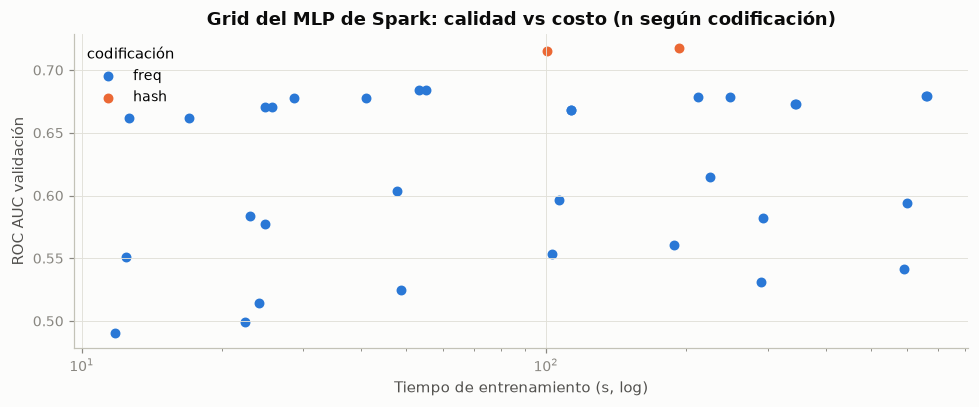

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (enc, g) in enumerate(grid_res.groupby("encoding")):
    g = g.sort_values("val_log_loss")
    lab = [f"{h} {s} {m} {so}" for h, s, m, so in zip(g["hidden"], g["stepSize"], g["maxIter"], g["solver"])]
    ax.scatter(g["train_s"], g["val_roc_auc"], color=SERIES[i], label=enc, s=30)
ax.set_xscale("log"); ax.set_xlabel("Tiempo de entrenamiento (s, log)"); ax.set_ylabel("ROC AUC validación")
ax.set_title("Grid del MLP de Spark: calidad vs costo (n según codificación)"); ax.legend(title="codificación")
savefig(fig, FIG, "05_grid_spark")

## 5.4 Corridas finales

In [6]:
done = done_keys(RUNS)
plan = []
for n in SC["sizes_freq"]:
    seeds = cfg.seeds if n in cfg["sk_seed_sizes"] else [cfg["seed_base"]]
    plan += [("freq", n, "lr", cfg["seed_base"])]
    if n is not None and n <= SC["gbt_max_size"]:
        plan += [("freq", n, "gbt", cfg["seed_base"])]
    plan += [("freq", n, "mlp", s) for s in seeds]
for n in SC["sizes_hash"]:
    seeds = cfg.seeds[: SC["hash_seeds"]]
    plan += [("hash", n, "lr", cfg["seed_base"])] + [("hash", n, "mlp", s) for s in seeds]

last_time = {}   # (enc, model) -> (n, segundos) para extrapolar
current = None
for enc, n, m, s in plan:
    key = run_key(fw="spark", model=m, enc=enc, n=n if n is not None else "all", seed=s, cw="none")
    if key in done:
        continue
    n_eff = n if n is not None else data.split_sizes(cfg)["train"]
    lt = last_time.get((enc, m))
    if lt and lt[1] * n_eff / lt[0] > budget_s:
        append_jsonl(RUNS, {"key": key, "framework": "spark", "model": m, "encoding": enc, "n": n_eff, "seed": s,
                            "omitida": True, "motivo": f"extrapolación {lt[1] * n_eff / lt[0] / 60:.0f} min > {SC['max_fit_minutes']} min"})
        print(f"OMITIDA {key}: extrapolación supera el presupuesto"); continue
    if current != (enc, n):
        if current is not None:
            for x in (trP, vaP, teP):
                x.unpersist()
        trP, vaP, teP, d, prep = prepare_all(n, enc, SC["hash_dim"])
        current = (enc, n)
    par = BEST.get(enc, {}) if m == "mlp" else {}
    rec, p_te, model = S.run_spark_model(m, par, trP, vaP, teP, d, s, yva, yte, va_ids, te_ids)
    rec.update({"key": key, "encoding": enc, "hash_dim": SC["hash_dim"] if enc == "hash" else None,
                "n": prep["n"], "n_train": prep["n"], "lectura_s": prep["lectura_s"], "prep_s": prep["prep_s"],
                "prep_peak_mb": prep["prep_peak_mb"], "params": par})
    if s == cfg["seed_base"]:
        rec["pred_file"] = save_preds(RES, key, p_te)
    append_jsonl(RUNS, rec)
    last_time[(enc, m)] = (prep["n"], rec["train_s"])
    print(f"n={prep['n']:>10,} {enc:5s} {m:4s} seed={s} AUC={rec['roc_auc']:.4f} ll={rec['log_loss']:.4f} train={rec['train_s']:.1f}s")

n=   100,000 freq  lr   seed=42 AUC=0.6563 ll=0.4326 train=2.3s


n=   100,000 freq  gbt  seed=42 AUC=0.6969 ll=0.4196 train=21.0s


n=   100,000 freq  mlp  seed=42 AUC=0.6835 ll=0.4241 train=15.6s


n=   100,000 freq  mlp  seed=43 AUC=0.6379 ll=0.4366 train=15.0s


n=   100,000 freq  mlp  seed=44 AUC=0.6724 ll=0.4283 train=14.8s


n=   100,000 freq  mlp  seed=45 AUC=0.6555 ll=0.4327 train=15.2s


... (11 outputs left out)

n=32,377,421 freq  lr   seed=42 AUC=0.6365 ll=0.4446 train=61.3s


n=32,377,421 freq  mlp  seed=42 AUC=0.6486 ll=0.4408 train=1064.8s


n=   100,000 hash  lr   seed=42 AUC=0.7088 ll=0.4281 train=5.1s


n=   100,000 hash  mlp  seed=42 AUC=0.7171 ll=0.4122 train=304.0s


## 5.5 Evidencia de la Spark UI (última sesión)

Además de la tabla siguiente (leída de la API REST de la UI), tome capturas de las pestañas
*Jobs*, *Stages* y *Storage* en http://localhost:4040 mientras corre el bloque 5.4 con el
entrenamiento completo, y guárdelas en `results/figures/spark_ui_*.png`.

In [7]:
ui = S.ui_stage_metrics(spark)
ui.to_csv(RES / "spark_ui_etapas.csv", index=False)
if "shuffleWriteBytes" in ui:
    resumen_ui = {"etapas": len(ui), "shuffle_lectura_GB": ui["shuffleReadBytes"].sum() / 2**30,
                  "shuffle_escritura_GB": ui["shuffleWriteBytes"].sum() / 2**30,
                  "spill_memoria_GB": ui["memoryBytesSpilled"].sum() / 2**30,
                  "spill_disco_GB": ui["diskBytesSpilled"].sum() / 2**30,
                  "sesgo_max_sobre_mediana_p95": float(ui["sesgo_max_sobre_mediana"].quantile(0.95))}
    print(resumen_ui)
    show(ui.sort_values("executorRunTime", ascending=False).head(10)[["stageId", "name", "numTasks", "executorRunTime",
         "shuffleReadBytes", "shuffleWriteBytes", "diskBytesSpilled", "sesgo_max_sobre_mediana"]])

{'etapas': 975, 'shuffle_lectura_GB': np.float64(0.01490007434040308), 'shuffle_escritura_GB': np.float64(0.01490007434040308), 'spill_memoria_GB': np.float64(0.0), 'spill_disco_GB': np.float64(0.0), 'sesgo_max_sobre_mediana_p95': 2.0}


,stageId,name,numTasks,executorRunTime,shuffleReadBytes,shuffleWriteBytes,diskBytesSpilled,sesgo_max_sobre_mediana
0,18774,toPandas at /content/deep-learning-01-ctr-mlp/...,8,4737332,0,0,0,1.0301
1,18773,toPandas at /content/deep-learning-01-ctr-mlp/...,7,820715,0,0,0,1.0375
934,17589,count at <unknown>:0,9,625379,0,0,0,1.0840
229,18544,count at <unknown>:0,8,339738,0,0,0,1.0521
880,17693,count at <unknown>:0,8,139993,0,0,0,1.0517
874,17700,treeAggregate at RDDLossFunction.scala:61,9,95158,0,10009,0,1.0926
414,18160,toPandas at /content/deep-learning-01-ctr-mlp/...,8,83554,0,0,0,1.0367
877,17697,treeAggregate at Summarizer.scala:238,9,76530,0,13766,0,1.1056
760,17814,treeAggregate at LBFGS.scala:261,9,74436,0,100368,0,1.0653
520,18054,treeAggregate at LBFGS.scala:261,9,72588,0,100368,0,1.0682


In [8]:
runs = read_jsonl(RUNS)
ok = runs[runs["omitida"].isna()] if "omitida" in runs else runs
tabla = summarize_runs(ok, ["n", "encoding", "model"], ["roc_auc", "pr_auc", "log_loss", "brier", "ece", "f1", "train_s", "train_peak_mb"])
tabla.to_csv(RES / "tabla_spark.csv", index=False)
show(tabla[["n", "encoding", "model", "n_semillas", "roc_auc_media", "roc_auc_sd", "roc_auc_ic", "pr_auc_media",
            "log_loss_media", "ece_media", "f1_media", "train_s_media", "train_peak_mb_media"]], 40)
if "omitida" in runs:
    show(runs[runs["omitida"].notna()][["model", "encoding", "n", "motivo"]])
spark.stop()

,n,encoding,model,n_semillas,roc_auc_media,roc_auc_sd,roc_auc_ic,pr_auc_media,log_loss_media,ece_media,f1_media,train_s_media,train_peak_mb_media
0,100000,freq,gbt,1,0.6969,NaN,n=1,0.3298,0.4196,0.0135,0.3859,20.9529,29098.5625
1,100000,freq,lr,1,0.6563,NaN,n=1,0.2775,0.4326,0.0175,0.3504,2.3393,27817.2500
2,100000,freq,mlp,5,0.6642,0.0178,"[0.6422, 0.6863]",0.3066,0.4299,0.0185,0.3452,15.0843,29088.0812
3,100000,hash,lr,1,0.7088,NaN,n=1,0.3375,0.4281,0.0336,0.3870,5.1340,35594.2969
4,100000,hash,mlp,1,0.7171,NaN,n=1,0.3408,0.4122,0.0132,0.3972,304.0169,35596.8555
5,1000000,freq,gbt,1,0.7026,NaN,n=1,0.3298,0.4187,0.0183,0.3844,41.7033,29466.3867
6,1000000,freq,lr,1,0.6501,NaN,n=1,0.2602,0.4357,0.0132,0.3498,6.3592,29490.3672
7,1000000,freq,mlp,5,0.6509,0.0214,"[0.6243, 0.6775]",0.2987,0.4323,0.0158,0.3405,41.1729,29433.5563
8,10000000,freq,gbt,1,0.7037,NaN,n=1,0.3307,0.4183,0.0150,0.3887,252.1424,35500.1680
9,10000000,freq,lr,1,0.6353,NaN,n=1,0.2410,0.4449,0.0307,0.3321,20.5040,33829.0195


## 5.6 Limitaciones del MLP de Spark (discusión obligatoria)

1. **Sin capas de embedding.** Cada categoría entra como una posición del vector (hashing) o como
   un escalar (frecuencia). Una red para CTR moderna (Wide & Deep, DeepFM, DCN) aprende un
   vector denso por categoría; MLlib no lo permite.
2. **Sin dropout ni regularización L2 configurable.** El único control del sobreajuste es
   `maxIter`/`tol`; no hay `alpha` como en scikit-learn ni parada temprana con validación.
3. **Activación sigmoide fija en ocultas y softmax en la salida.** No hay ReLU: gradientes que se
   desvanecen con redes profundas, lo que explica que `[d,128,64,2]` no necesariamente mejore.
4. **Entrada densificada por bloques.** El costo crece con la dimensión del hashing y no con el
   número de no ceros (evidencia en el grid 5.3 y en las corridas omitidas).
5. **Solo `l-bfgs` (lote completo) o `gd`.** No hay Adam ni minibatches, que son los que
   convergen rápido en datos grandes y ruidosos como los de CTR.

**Extensión opcional (no ejecutada aquí):** una red con embeddings entrenada de forma
distribuida con `TorchDistributor`, para comparar contra el MLP nativo.